# 합성 이미지 생성 v2

[v1 대비 변경 사항]
1. 합성 분량: 1000 → 7200 (양질 1800 + 신규 5400 통합 분량)
2. 알약 개수: 1~4개, 양질 분포 가중 샘플링 (1개 13.5% / 2개 42.9% / 3개 31.1% / 4개 12.4%)
3. 알약 크기: 양질 1800 측정 분포 기반 lognormal 샘플링 (개수별 mean/std 분리)
   - 1개: mean -0.68, std 0.131 (클로즈업)
   - 2개: mean -1.25, std 0.585
   - 3-4개: mean -1.45, std 0.564
   - 화질 보호: 원본보다 큰 목표 area_ratio 회피 (업스케일 X)
4. 합성 후 검증: 양질 ±1σ 안에 분포 들어왔는지 측정

**먼저 셀 4의 `N_SYNTH=10`으로 dry-run → OK면 7200으로 바꿔서 본 실행**


## 1. 환경 설정

In [40]:
import os
import cv2
import random
import pickle
import numpy as np
from collections import Counter
from pathlib import Path
from PIL import Image

# 경로 설정
BG_DIR        = Path(r"D:\pill_detection\synthetic_bg")
SYNTH_DIR     = Path(r"D:\pill_detection\synthetic_v2")
SYNTH_IMG_DIR = SYNTH_DIR / "images" / "train"
SYNTH_LBL_DIR = SYNTH_DIR / "labels" / "train"
CROPS_CACHE   = Path(r"D:\pill_detection\crops_cache.pkl")

SYNTH_IMG_DIR.mkdir(parents=True, exist_ok=True)
SYNTH_LBL_DIR.mkdir(parents=True, exist_ok=True)

print(f"배경 폴더: {BG_DIR} (존재: {BG_DIR.exists()})")
print(f"피클 파일: {CROPS_CACHE} (존재: {CROPS_CACHE.exists()})")
print(f"출력 폴더: {SYNTH_DIR}")

배경 폴더: D:\pill_detection\synthetic_bg (존재: True)
피클 파일: D:\pill_detection\crops_cache.pkl (존재: True)
출력 폴더: D:\pill_detection\synthetic_v2


## 2. 합성 설정

In [41]:
IMG_W               = 976
IMG_H               = 1280
IMG_AREA            = IMG_W * IMG_H
N_SYNTH             = 805            # ★ dry-run: 10 / 본 실행: 7200
START_IDX           = 7195 
MIN_PILLS           = 1             # v2: 2 → 1로 낮춤
MAX_PILLS           = 4
MARGIN              = 30
MAX_PILL_AREA_POST  = 0.50          # v2: 0.30 → 0.50 (1개 클로즈업 대응)

# v2 신규 — 양질 1800 측정 기반
PILL_COUNT_WEIGHTS = {
    1: 0.135,   # 양질 1개 비율
    2: 0.429,
    3: 0.311,
    4: 0.124,
}

# 양질 알약 개수별 area_ratio 분포 (log10 공간, mean / std)
PILL_SIZE_DIST = {
    1: {'mean': -0.68, 'std': 0.131},
    2: {'mean': -1.25, 'std': 0.585},
    3: {'mean': -1.45, 'std': 0.564},  # 3-4 묶여 측정됨
    4: {'mean': -1.45, 'std': 0.564},
}

SIGMA_CLIP     = 2.0    # 양질 ±2σ 밖 추출값 클리핑 (극단 outlier 방지)
MAX_SIZE_RETRY = 30     # lognormal 재추출 최대 시도 횟수 (화질 보호)

# 배경 카테고리 (BG_DIR 하위 폴더 명시. _test 같은 작업용 폴더 자동 제외)
BG_CATEGORIES = [
    'dark_surface', 'fabric', 'gray_surface',
    'marble_tile', 'palm_hand', 'white_paper',
]

random.seed(43)
np.random.seed(43)

print(f"N_SYNTH = {N_SYNTH}")
print(f"이미지당 알약 {MIN_PILLS}~{MAX_PILLS}개 (양질 가중치)")
print(f"개수 가중치: {PILL_COUNT_WEIGHTS}")

N_SYNTH = 805
이미지당 알약 1~4개 (양질 가중치)
개수 가중치: {1: 0.135, 2: 0.429, 3: 0.311, 4: 0.124}


## 3. 유틸 함수

In [42]:
def boxes_overlap(new_box, placed_boxes, img_area):
    """15% 이상 겹치면 충돌."""
    nx1, ny1, nx2, ny2 = new_box
    for bx1, by1, bx2, by2 in placed_boxes:
        ix1 = max(nx1, bx1); iy1 = max(ny1, by1)
        ix2 = min(nx2, bx2); iy2 = min(ny2, by2)
        if ix2 > ix1 and iy2 > iy1:
            inter = (ix2 - ix1) * (iy2 - iy1)
            new_area = (nx2 - nx1) * (ny2 - ny1)
            if inter / new_area > 0.15:
                return True
    return False


def sample_n_pills():
    """양질 분포 가중치로 알약 개수 샘플링."""
    keys = list(PILL_COUNT_WEIGHTS.keys())
    weights = list(PILL_COUNT_WEIGHTS.values())
    return random.choices(keys, weights=weights, k=1)[0]


def sample_target_size(n_pills, orig_w, orig_h):
    """
    양질 분포 기반 목표 크기 결정. 업스케일 허용.

    각인 학습을 위해 알약을 충분히 크게 합성하는 것이 우선.
    화질 저하는 LANCZOS 보간으로 어느 정도 보완.
    이미지 너비/높이를 벗어나는 경우 비율 유지하며 클리핑.
    """
    dist = PILL_SIZE_DIST[n_pills]
    mean, std = dist['mean'], dist['std']

    log_min = mean - SIGMA_CLIP * std
    log_max = mean + SIGMA_CLIP * std

    log_sample = np.random.normal(mean, std)
    log_sample = np.clip(log_sample, log_min, log_max)
    target_ratio = 10 ** log_sample

    orig_area_ratio = (orig_w * orig_h) / IMG_AREA
    scale = (target_ratio / orig_area_ratio) ** 0.5
    tw = max(10, int(orig_w * scale))
    th = max(10, int(orig_h * scale))

    # 이미지 영역 안에 들어가도록 클리핑 (비율 유지)
    max_w = IMG_W - 2 * MARGIN
    max_h = IMG_H - 2 * MARGIN
    if tw > max_w or th > max_h:
        clip_scale = min(max_w / tw, max_h / th)
        tw = max(10, int(tw * clip_scale))
        th = max(10, int(th * clip_scale))

    return tw, th

## 4. 피클 로드 (알약 누끼 7503개)

기존 `crops_cache.pkl` 그대로 사용. 항목 키: `img` / `class_idx` / `w` / `h`.

In [43]:
print(f"피클 로드 중... ({CROPS_CACHE.stat().st_size / (1024**3):.2f} GB)")
with open(CROPS_CACHE, "rb") as f:
    crops = pickle.load(f)

print(f"  → 총 {len(crops)}개 누끼")
print(f"  → 첫 원소 키: {list(crops[0].keys())}")

# 클래스별 인덱스 맵 (클래스 균등 샘플링)
class_map = {}
for i, c in enumerate(crops):
    class_map.setdefault(c["class_idx"], []).append(i)

print(f"  → 클래스 수: {len(class_map)}")
print(f"  → 클래스당 평균 누끼: {len(crops) / len(class_map):.1f}개")

피클 로드 중... (2.51 GB)
  → 총 7503개 누끼
  → 첫 원소 키: ['img', 'class_idx', 'w', 'h']
  → 클래스 수: 118
  → 클래스당 평균 누끼: 63.6개


## 5. 배경 이미지 로드 (카테고리별)

`BG_CATEGORIES` 에 명시된 6개 폴더만 검색. `_test`, `_texture_test` 같은 작업용 폴더 자동 제외.

In [44]:
bg_files = []
print(f"배경 카테고리별 이미지 수:")
for cat in BG_CATEGORIES:
    cat_dir = BG_DIR / cat
    if not cat_dir.exists():
        print(f"  [경고] {cat}: 폴더 없음 ({cat_dir})")
        continue
    cat_files = (
        list(cat_dir.glob("*.jpg")) +
        list(cat_dir.glob("*.jpeg")) +
        list(cat_dir.glob("*.png"))
    )
    bg_files.extend(cat_files)
    print(f"  {cat:>15}: {len(cat_files)}장")

print(f"\n총 배경 이미지 수: {len(bg_files)}장")

backgrounds = []
for p in bg_files:
    img = cv2.imread(str(p))
    if img is not None:
        img = cv2.resize(img, (IMG_W, IMG_H))
        backgrounds.append(img)

print(f"로드 완료: {len(backgrounds)}장 ({IMG_W}x{IMG_H} 리사이즈)")
assert len(backgrounds) > 0, "배경 0장이면 합성 못 함"

배경 카테고리별 이미지 수:
     dark_surface: 42장
           fabric: 39장
     gray_surface: 51장
      marble_tile: 27장
        palm_hand: 6장
      white_paper: 24장

총 배경 이미지 수: 189장
로드 완료: 189장 (976x1280 리사이즈)


## 6. 합성 실행

[v2 핵심]
- 알약 개수: `sample_n_pills()` (양질 가중치)
- 알약 크기: `sample_target_size()` (양질 lognormal + 화질 보호)

In [45]:
print(f"\n합성 시작 (총 {N_SYNTH}장 목표)")
print(f"  배경 {len(backgrounds)}개 → 한 배경당 평균 {N_SYNTH / len(backgrounds):.1f}회 사용\n")

success = 0

for img_idx in range(START_IDX, START_IDX + N_SYNTH):
    # 배경 선택 (순환)
    bg = backgrounds[img_idx % len(backgrounds)].copy()
    
    # v2: 알약 개수 가중 샘플링
    n_pills = sample_n_pills()
    
    placed_boxes = []
    labels = []

    for _ in range(n_pills):
        # 클래스 균등 샘플링
        cls_idx  = random.choice(list(class_map.keys()))
        crop_idx = random.choice(class_map[cls_idx])
        crop_info = crops[crop_idx]
        rgba = crop_info["img"]   # 키 이름: img (cache 형식)
        orig_w, orig_h = rgba.size
        
        # v2: 양질 분포 기반 목표 크기 결정 (화질 보호)
        cw, ch = sample_target_size(n_pills, orig_w, orig_h)
        if (cw, ch) != (orig_w, orig_h):
            rgba = rgba.resize((cw, ch), Image.LANCZOS)

        for _ in range(30):
            px = random.randint(MARGIN, max(MARGIN + 1, IMG_W - cw - MARGIN))
            py = random.randint(MARGIN, max(MARGIN + 1, IMG_H - ch - MARGIN))
            new_box = (px, py, px + cw, py + ch)

            post_ratio = (cw * ch) / IMG_AREA
            if post_ratio > MAX_PILL_AREA_POST:
                continue
            if boxes_overlap(new_box, placed_boxes, IMG_AREA):
                continue

            rgba_np  = np.array(rgba)
            alpha    = rgba_np[:, :, 3:4] / 255.0
            pill_rgb = rgba_np[:, :, :3][:, :, ::-1]   # RGB → BGR

            roi = bg[py:py + ch, px:px + cw]
            blended = (pill_rgb * alpha + roi * (1 - alpha)).astype(np.uint8)
            bg[py:py + ch, px:px + cw] = blended

            placed_boxes.append(new_box)

            cx_n = (px + cw / 2) / IMG_W
            cy_n = (py + ch / 2) / IMG_H
            bw_n = cw / IMG_W
            bh_n = ch / IMG_H
            labels.append(f"{cls_idx} {cx_n:.6f} {cy_n:.6f} {bw_n:.6f} {bh_n:.6f}")
            break

    if not labels:
        continue

    fname = f"synth_{img_idx:05d}"
    cv2.imwrite(str(SYNTH_IMG_DIR / f"{fname}.jpg"), bg)
    with open(SYNTH_LBL_DIR / f"{fname}.txt", "w") as f:
        f.write("\n".join(labels))

    success += 1
    if success % 100 == 0:
        print(f"  [{success}/{N_SYNTH}] 생성 중...")

print(f"\n완료: {success}장 생성")
print(f"  이미지: {SYNTH_IMG_DIR}")
print(f"  라벨:   {SYNTH_LBL_DIR}")


합성 시작 (총 805장 목표)
  배경 189개 → 한 배경당 평균 4.3회 사용

  [100/805] 생성 중...
  [200/805] 생성 중...
  [300/805] 생성 중...
  [400/805] 생성 중...
  [500/805] 생성 중...
  [600/805] 생성 중...
  [700/805] 생성 중...
  [800/805] 생성 중...

완료: 804장 생성
  이미지: D:\pill_detection\synthetic_v2\images\train
  라벨:   D:\pill_detection\synthetic_v2\labels\train


## 7. 라벨 검증 + 양질 분포 매칭 검증

[v2 신규] 합성 분포가 양질 ±1σ 안에 들어왔는지 측정.

In [46]:
img_files = list(SYNTH_IMG_DIR.glob("*.jpg"))

total_anno  = 0
range_err   = 0

pill_counts    = []                          # 이미지당 알약 개수
pills_by_count = {1: [], 2: [], 3: [], 4: []}   # 알약 개수별 area_ratio (log10)

for img_path in img_files:
    lbl_path = SYNTH_LBL_DIR / (img_path.stem + ".txt")
    if not lbl_path.exists():
        continue
    with open(lbl_path) as f:
        lines = [l.strip() for l in f if l.strip()]
    if not lines:
        continue
    
    n = len(lines)
    pill_counts.append(n)
    
    for line in lines:
        parts = line.split()
        if len(parts) < 5:
            continue
        total_anno += 1
        _, cx, cy, bw, bh = map(float, parts[:5])
        if not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
            range_err += 1
        
        area_ratio = bw * bh
        if area_ratio > 0 and n in pills_by_count:
            pills_by_count[n].append(np.log10(area_ratio))

# ─ 기본 검증 ─
print("[기본 검증]")
print(f"  이미지       : {len(img_files)}장")
print(f"  annotation   : {total_anno}개")
print(f"  이미지당 평균 : {total_anno / max(len(img_files), 1):.2f}개")
print(f"  범위 초과    : {range_err}개 (0이어야 정상)")

# ─ 양질 알약 개수 분포 비교 ─
if pill_counts:
    cnt = Counter(pill_counts)
    print("\n[알약 개수 분포 — 양질 비교]")
    print(f"  {'개수':>4} | {'합성':>14} | {'양질 목표':>10}")
    print(f"  " + "-" * 36)
    for k in sorted(cnt.keys()):
        pct = cnt[k] / len(pill_counts) * 100
        target = PILL_COUNT_WEIGHTS.get(k, 0) * 100
        print(f"  {k:>4}개 | {cnt[k]:>5}장 ({pct:>5.1f}%) | {target:>5.1f}%")

# ─ 양질 ±1σ 매칭 검증 ─
print("\n[알약 개수별 area_ratio 분포 — 양질 ±1σ 매칭]")
print(f"  {'개수':>4} | {'n':>5} | {'합성 mean':>10} | {'합성 std':>9} | "
      f"{'양질 mean':>10} | {'양질 std':>9} | {'±1σ 안':>10}")
print(f"  " + "-" * 80)
for n_pill in sorted(pills_by_count.keys()):
    vals = pills_by_count[n_pill]
    if not vals:
        continue
    target = PILL_SIZE_DIST[n_pill]
    target_min = target['mean'] - target['std']
    target_max = target['mean'] + target['std']
    
    in_range = sum(1 for v in vals if target_min <= v <= target_max)
    in_range_pct = in_range / len(vals) * 100
    
    print(f"  {n_pill:>4}개 | {len(vals):>5} | "
          f"{np.mean(vals):>10.3f} | {np.std(vals):>9.3f} | "
          f"{target['mean']:>10.3f} | {target['std']:>9.3f} | "
          f"{in_range_pct:>9.1f}%")

[기본 검증]
  이미지       : 7994장
  annotation   : 18801개
  이미지당 평균 : 2.35개
  범위 초과    : 0개 (0이어야 정상)

[알약 개수 분포 — 양질 비교]
    개수 |             합성 |      양질 목표
  ------------------------------------
     1개 |  1496장 ( 18.7%) |  13.5%
     2개 |  3111장 ( 38.9%) |  42.9%
     3개 |  2465장 ( 30.8%) |  31.1%
     4개 |   922장 ( 11.5%) |  12.4%

[알약 개수별 area_ratio 분포 — 양질 ±1σ 매칭]
    개수 |     n |    합성 mean |    합성 std |    양질 mean |    양질 std |      ±1σ 안
  --------------------------------------------------------------------------------
     1개 |  1496 |     -0.790 |     0.368 |     -0.680 |     0.131 |      52.7%
     2개 |  6222 |     -1.314 |     0.512 |     -1.250 |     0.585 |      72.5%
     3개 |  7395 |     -1.463 |     0.529 |     -1.450 |     0.564 |      69.4%
     4개 |  3688 |     -1.503 |     0.529 |     -1.450 |     0.564 |      69.4%


## 8. 샘플 시각화

생성된 이미지 중 알약 개수별로 1장씩 미리보기.

C:\Users\user\AppData\Local\Temp\ipykernel_9920\2602010785.py:42: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Local\Temp\ipykernel_9920\2602010785.py:42: UserWarning: Glyph 50508 (\N{HANGUL SYLLABLE AL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Local\Temp\ipykernel_9920\2602010785.py:42: UserWarning: Glyph 50557 (\N{HANGUL SYLLABLE YAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


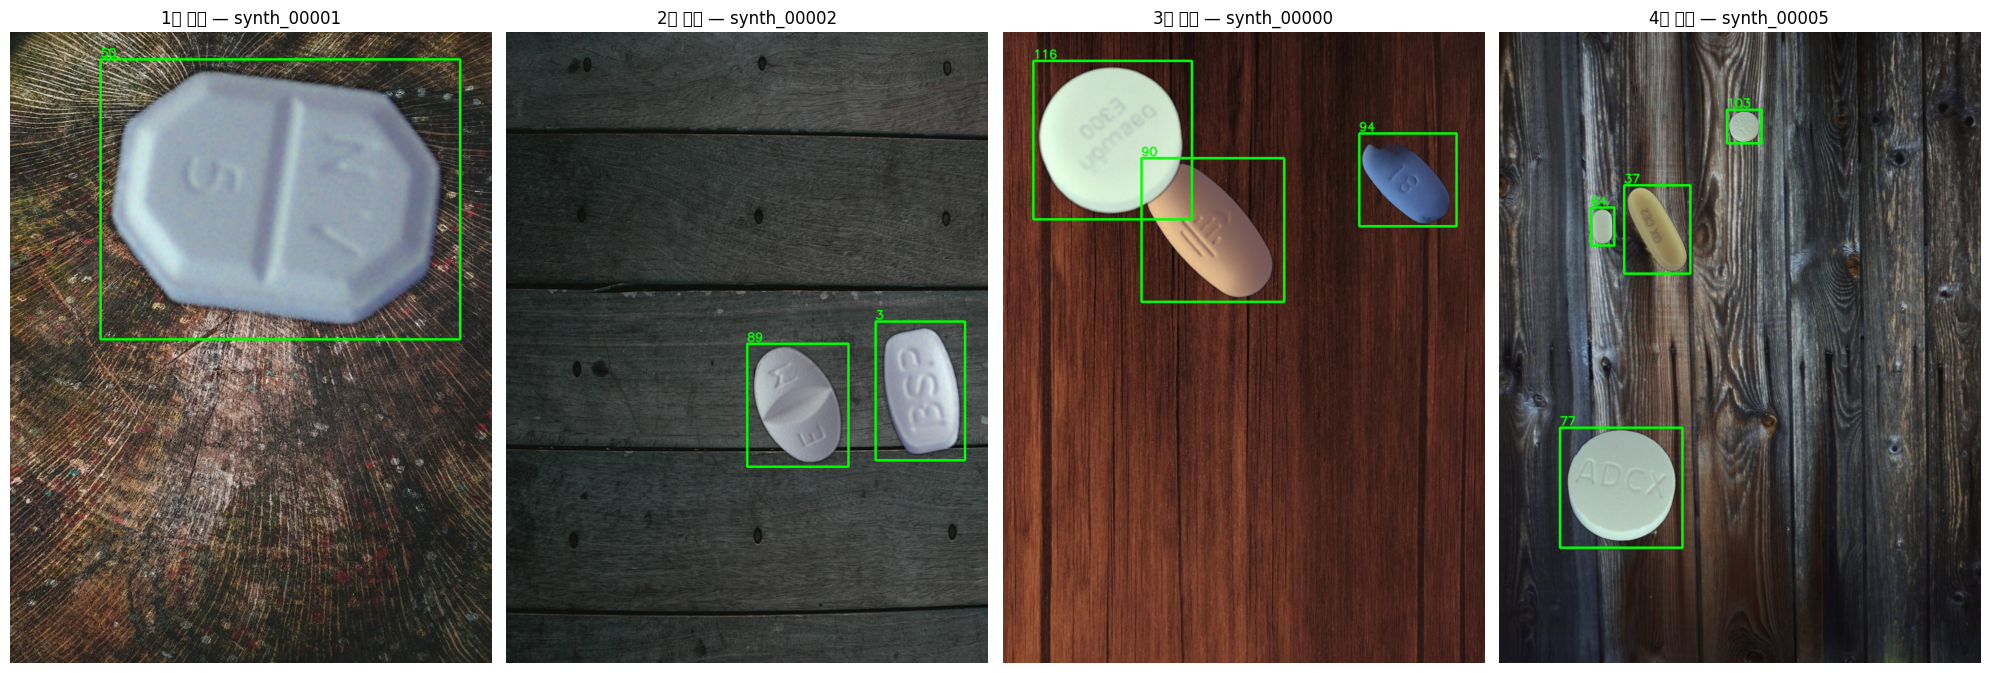

In [48]:
import matplotlib.pyplot as plt

# 알약 개수별로 1장씩 샘플 선택
samples_by_count = {1: None, 2: None, 3: None, 4: None}
for img_path in sorted(SYNTH_IMG_DIR.glob("*.jpg")):
    lbl_path = SYNTH_LBL_DIR / (img_path.stem + ".txt")
    if not lbl_path.exists():
        continue
    with open(lbl_path) as f:
        n = len([l for l in f if l.strip()])
    if n in samples_by_count and samples_by_count[n] is None:
        samples_by_count[n] = img_path
    if all(v is not None for v in samples_by_count.values()):
        break

# 시각화
sample_paths = [(n, p) for n, p in samples_by_count.items() if p is not None]
if sample_paths:
    fig, axes = plt.subplots(1, len(sample_paths), figsize=(5 * len(sample_paths), 7))
    if len(sample_paths) == 1:
        axes = [axes]
    
    for ax, (n_pill, img_path) in zip(axes, sample_paths):
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        lbl_path = SYNTH_LBL_DIR / (img_path.stem + ".txt")
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                cls, cx, cy, bw, bh = parts[0], *map(float, parts[1:5])
                x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
                x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
                cv2.putText(img, cls, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

        ax.imshow(img)
        ax.set_title(f"{n_pill}개 알약 — {img_path.stem}")
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("생성된 이미지 없음")